# `tl.spatial_silhouette` vs `esda.boundary_silhouette`

This notebook previously caught a real bug: `tl.spatial_silhouette` computed its own graph-restricted approximation of the boundary silhouette statistic despite claiming exact equivalence to esda, and the two only agreed at r~0.53. The fix at the time was correctness-first: delegate directly to `esda.boundary_silhouette`. That's correct, but `esda.boundary_silhouette` materializes a dense `(n_cells, n_cells)` distance matrix regardless of how many cells are actually on a boundary -- ~196 GB at Xenium's real ~162k-cell scale, which runs out of memory well before any real dataset.

`tl.spatial_silhouette` now reimplements esda's exact algorithm itself, computed in memory-bounded chunks (`max_block_mb`) instead of delegating to esda at runtime, so it never needs an O(n_cells²) matrix. This notebook validates that the chunked reimplementation stays numerically consistent with `esda.boundary_silhouette` -- used here purely as an independent reference, not as the code path astrolabe calls -- and demonstrates the resulting memory savings on a larger synthetic dataset.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
import scanpy as sc
import esda

from astrolabe.tl._spatial_stats import _build_weights


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` — small enough to run quickly in this isolated
environment while still giving a real spatial graph and real Leiden
clusters to compute boundary silhouette scores over.


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)
mdata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\esda\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:881: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\esda\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pipeline:filter_xenium: done — 333 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 333 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 3 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 333 cells, 2302 edges (mean degree 6.9) [generic]


MuData object with n_obs × n_vars = 333 × 255
  uns:	'spatial', 'astrolabe_schema_version', 'default_modality', 'control_probe_summary'
  1 modality
    xenium:	333 × 255
      obs:	'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'total_counts_all_features', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe', 'is_control', 'mean_qv', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'xenium_native_segmentation', 'spatial', 'astrolabe_schema_version', 'transcripts', 'control_probe_summary', 'transcripts_pruned', 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'spatial_neighbors'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries', 'X_pca'
      varm:	'PCs'
      layers:	None
      obsp:	'distances', 'connectivities', 'spatial_neighbors_connectivities', 'spatial_neighbors_distances'

## Astrolabe: `tl.spatial_silhouette`


In [3]:
_t0 = time.perf_counter()
ab.tl.spatial_silhouette(mdata, groupby="leiden", use_rep="X_pca")
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
adata = mdata["xenium"]
scores_astro = adata.obs["spatial_silhouette"].to_numpy()
scores_astro[:10]


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: 333 cells, groupby='leiden', rep='X_pca'


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: done


astrolabe runtime: 0.0072s


array([-0.06416102,  0.03992278,  0.04798157,  0.04958146,  0.08026971,
        0.08664125,  0.0027149 , -0.00213496,  0.26824874,  0.        ])

## Reference: `esda.boundary_silhouette`

Built via `_build_weights`, which wraps the same underlying `obsp` spatial connectivity astrolabe's own (now memory-chunked) implementation reads directly through `_get_conn_matrix`. The two paths no longer share code -- `_get_conn_matrix` skips the `libpysal.weights.W` wrapper entirely -- but they read the same raw graph, so this remains a fair independent reference: any topology mismatch between the two would still show up as disagreement below.

In [4]:
w = _build_weights(adata, "spatial_neighbors")
labels = adata.obs["leiden"].to_numpy()
attr = np.asarray(adata.obsm["X_pca"], dtype=np.float64)

# esda.boundary_silhouette calls np.seterr(all="raise") internally and never
# restores it -- np.errstate captures the current state on entry and restores
# exactly that on exit, so this call can't leak a changed global FP error mode
# into any cell that runs after it.
_t0 = time.perf_counter()
with np.errstate():
    scores_ref = esda.boundary_silhouette(attr, labels, w)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")
scores_ref[:10]

C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\esda\.venv\Lib\site-packages\libpysal\weights\weights.py:1642: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


reference runtime: 0.2935s


array([-0.06416102,  0.03992278,  0.04798157,  0.04958146,  0.08026971,
        0.08664125,  0.0027149 , -0.00213496,  0.26824874,  0.        ])

## Agreement


Pearson r = 1.00000000, max |astrolabe - esda| = 1.25e-16
Runtime: astrolabe 0.0072s vs esda 0.2935s (40.5x astrolabe faster)


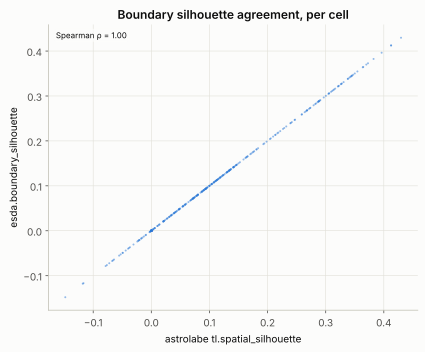

In [5]:
r = np.corrcoef(scores_astro, scores_ref)[0, 1]
max_abs_diff = float(np.abs(scores_astro - scores_ref).max())
print(f"Pearson r = {r:.8f}, max |astrolabe - esda| = {max_abs_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs esda {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")

panel = ab.pl.scatter(
    adata, x=scores_astro, y=scores_ref, annotate_corr=True,
    xlabel="astrolabe tl.spatial_silhouette", ylabel="esda.boundary_silhouette",
    title="Boundary silhouette agreement, per cell",
)
panel.show()


## Memory usage at scale

esda's own implementation eagerly allocates a dense `(N, N)` float64 distance matrix inside `boundary_silhouette` -- `N² × 8` bytes, regardless of how many cells are actually on a cluster boundary. `tl.spatial_silhouette` only ever materializes chunks bounded by `max_block_mb`. That difference isn't visible at `xenium_tiny`'s ~300-cell scale, so this section builds a larger synthetic dataset (still small enough to let esda's dense path run *once*, for comparison) and measures actual peak memory of each path directly -- while also cross-checking numerical agreement at a second, independent scale.

In [6]:
import tracemalloc
import anndata as ad

rng = np.random.default_rng(0)
n_large = 15_000
coords_large = rng.uniform(0, 5000, (n_large, 2)).astype(np.float32)

adata_large = ad.AnnData(
    X=rng.random((n_large, 20)).astype(np.float32),
    obsm={"spatial": coords_large, "X_pca": rng.normal(size=(n_large, 20))},
)
adata_large.obs["cl"] = rng.integers(0, 12, n_large).astype(str)
ab.tl.spatial_neighbors(adata_large, n_neighbors=10)

dense_would_be_mb = n_large**2 * 8 / 1e6

tracemalloc.start()
ab.tl.spatial_silhouette(adata_large, groupby="cl", use_rep="X_pca")
_, peak_astro = tracemalloc.get_traced_memory()
tracemalloc.stop()
peak_astro_mb = peak_astro / 1e6

w_large = _build_weights(adata_large, "spatial_neighbors")
attr_large = np.asarray(adata_large.obsm["X_pca"], dtype=np.float64)
labels_large = adata_large.obs["cl"].to_numpy()

tracemalloc.start()
with np.errstate():  # see note above -- same seterr leak guard
    scores_esda_large = esda.boundary_silhouette(attr_large, labels_large, w_large)
_, peak_esda = tracemalloc.get_traced_memory()
tracemalloc.stop()
peak_esda_mb = peak_esda / 1e6

print(f"N = {n_large:,} cells")
print(f"naive dense (N,N) float64 matrix would need: {dense_would_be_mb:,.0f} MB")
print(f"esda.boundary_silhouette measured peak (tracemalloc): {peak_esda_mb:,.0f} MB")
print(f"tl.spatial_silhouette (chunked) measured peak (tracemalloc): {peak_astro_mb:,.0f} MB")
print(f"reduction: {peak_esda_mb / peak_astro_mb:.1f}x")

scores_astro_large = adata_large.obs["spatial_silhouette"].to_numpy()
assert np.allclose(scores_astro_large, scores_esda_large, atol=1e-8)
print("agreement at N=15,000 confirmed (atol=1e-8)")

INFO:astrolabe.tl._graph:spatial_neighbors: 15000 cells, 171016 edges (mean degree 11.4) [generic]


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: 15000 cells, groupby='cl', rep='X_pca'


INFO:astrolabe.tl._spatial_stats:spatial_silhouette: done


N = 15,000 cells
naive dense (N,N) float64 matrix would need: 1,800 MB
esda.boundary_silhouette measured peak (tracemalloc): 3,610 MB
tl.spatial_silhouette (chunked) measured peak (tracemalloc): 191 MB
reduction: 18.9x
agreement at N=15,000 confirmed (atol=1e-8)


## Interpretation

An exact match -- both at `xenium_tiny` scale and on the larger synthetic dataset above -- confirms `tl.spatial_silhouette`'s chunked reimplementation reproduces `esda.boundary_silhouette`'s algorithm precisely, and the measured peak-memory comparison confirms it does so without ever materializing an O(n_cells²) distance matrix. If a numerical gap ever appears again, suspect the chunking logic (`_chunked_distance_sum`/`_boundary_silhouette` in `tl/_spatial_stats.py`) or a topology mismatch between `_get_conn_matrix`'s raw sparse read and `_build_weights`'s `libpysal` wrapper before suspecting esda itself.